# Principal Component Analysis(PCA)

In [1]:
student_name='\u0905\u092D\u093F\u091C\u0940\u0924\u0020\u0915\u0941\u092E\u093E\u0930'
print("STUDENT NAME: ",student_name)

STUDENT NAME:  अभिजीत कुमार


In [2]:
submited_to='\u0935\u0948\u0936\u093E\u0932\u0940\u0020\u0907\u0902\u0917\u0933\u0947'
print("SUBMITED TO: ",submited_to)

SUBMITED TO:  वैशाली इंगळे


#### IMPORTING LIBRARIES

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler, MinMaxScaler , LabelEncoder
from sklearn.model_selection import train_test_split

from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report , confusion_matrix

#### LOADING DATASET

In [4]:
df=pd.read_csv("Wine.csv")

print("Number of samples:", df.shape[0])
print("Number of features:", df.shape[1])
df.head(5)

Number of samples: 178
Number of features: 14


,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline,Customer_Segment
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1


In [5]:
df["Customer_Segment"].unique()

array([1, 2, 3])

#### DATA ANALYSIS

In [6]:
print("Missing values:")
print(df.isnull().sum())

if(df.duplicated().sum()==0):
  print("\nNo duplicate rows present.")
else:
  print("\nDuplicate rows:", df.duplicated().sum())


Missing values:
Alcohol                 0
Malic_Acid              0
Ash                     0
Ash_Alcanity            0
Magnesium               0
Total_Phenols           0
Flavanoids              0
Nonflavanoid_Phenols    0
Proanthocyanins         0
Color_Intensity         0
Hue                     0
OD280                   0
Proline                 0
Customer_Segment        0
dtype: int64

No duplicate rows present.


#### DEPENDENT AND INDEPENDENT FEATURES

In [7]:
X = df.drop("Customer_Segment", axis=1)
y = df["Customer_Segment"]

print("Input features shape:", X.shape)
print("Output variable shape:", y.shape)

Input features shape: (178, 13)
Output variable shape: (178,)


#### SCALING

In [8]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Shape after standardization:", X_scaled.shape)

Shape after standardization: (178, 13)


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)


Training data shape: (142, 13)
Testing data shape: (36, 13)


In [10]:
model = KNeighborsClassifier(n_neighbors=5)
model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print("Training Accuracy:", accuracy_score(y_train, y_train_pred))
print("Testing Accuracy:", accuracy_score(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

Training Accuracy: 0.9788732394366197
Testing Accuracy: 0.9722222222222222

Classification Report:
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        12
           2       1.00      0.93      0.96        14
           3       0.91      1.00      0.95        10

    accuracy                           0.97        36
   macro avg       0.97      0.98      0.97        36
weighted avg       0.97      0.97      0.97        36



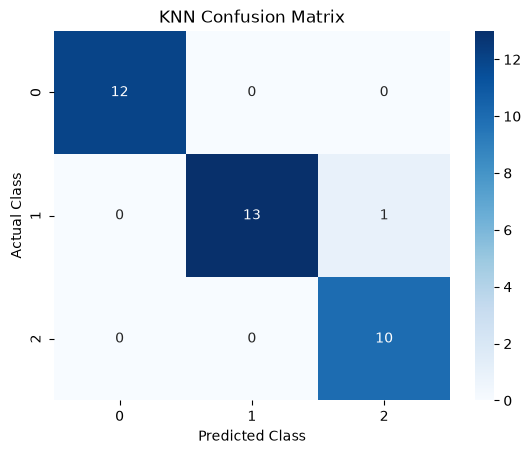

In [11]:
cm = confusion_matrix(y_test, y_test_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("KNN Confusion Matrix")
plt.show()

#### PRINCIPAL COMPONENT ANALYSIS

In [12]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["quality"] = y.values

pca_df.head()

,PC1,PC2,quality
0,3.316751,1.443463,1
1,2.209465,-0.333393,1
2,2.516740,1.031151,1
3,3.757066,2.756372,1
4,1.008908,0.869831,1


In [13]:
X = pca_df[["PC1", "PC2"]]
y = pca_df["quality"]

X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42,stratify=y)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (142, 2)
Testing shape: (36, 2)


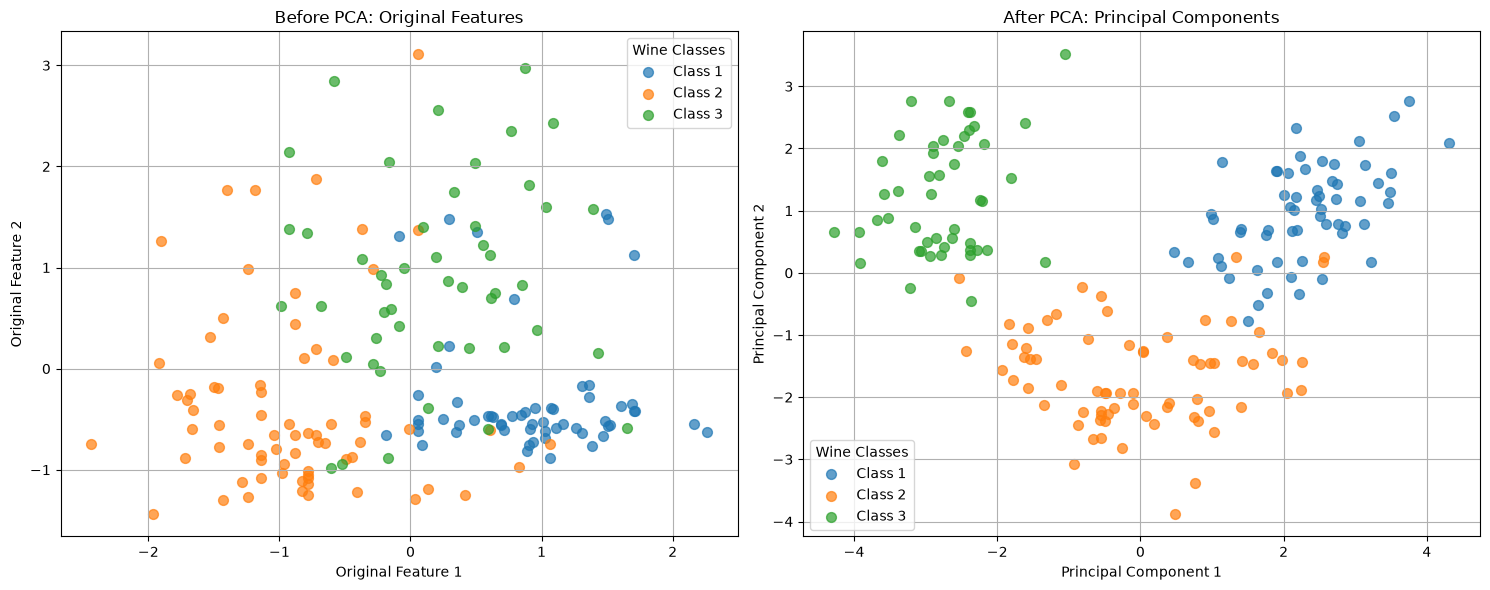

In [14]:
# Get the original class labels
class_labels = df["Customer_Segment"].to_numpy()
unique_classes = np.unique(class_labels)

# Create two graphs side by side
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# BEFORE PCA: First two original features
for class_label in unique_classes:
    mask = class_labels == class_label

    axes[0].scatter(
        X_scaled[mask, 0],
        X_scaled[mask, 1],
        label=f"Class {class_label}",
        alpha=0.7,
        s=50
    )

axes[0].set_title("Before PCA: Original Features")
axes[0].set_xlabel("Original Feature 1")
axes[0].set_ylabel("Original Feature 2")
axes[0].legend(title="Wine Classes")
axes[0].grid(True)

# AFTER PCA: First two principal components
for class_label in unique_classes:
    mask = class_labels == class_label

    axes[1].scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=f"Class {class_label}",
        alpha=0.7,
        s=50
    )

axes[1].set_title("After PCA: Principal Components")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")
axes[1].legend(title="Wine Classes")
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [15]:
variance_df = pd.DataFrame({
    "Principal Component": ["PC1", "PC2"],
    "Explained Variance Ratio": pca.explained_variance_ratio_
})

print(variance_df)

  Principal Component  Explained Variance Ratio
0                 PC1                  0.361988
1                 PC2                  0.192075


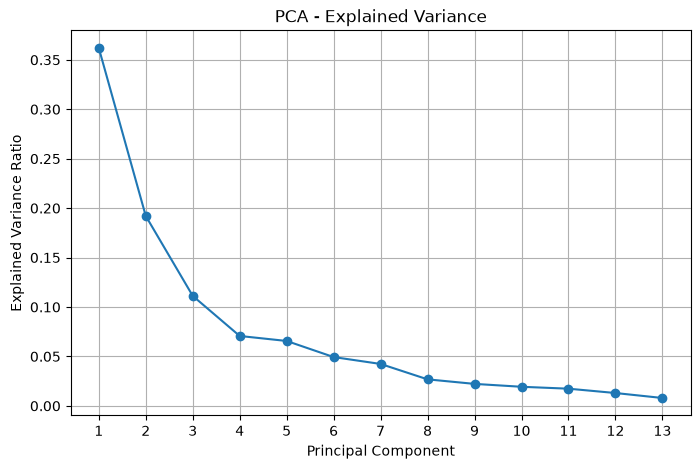

In [16]:
# Fit PCA on all components
pca_full = PCA()
pca_full.fit(X_scaled)

# Plot explained variance
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(pca_full.explained_variance_ratio_) + 1),
    pca_full.explained_variance_ratio_,
    marker='o'
)

plt.xlabel("Principal Component")
plt.ylabel("Explained Variance Ratio")
plt.title("PCA - Explained Variance")
plt.xticks(range(1, len(pca_full.explained_variance_ratio_) + 1))
plt.grid(True)
plt.show()


In [17]:
pca_df = pd.DataFrame(X_pca,columns=["PC1", "PC2"])

pca_df["quality"] = y.values

pca_df.head(5)

,PC1,PC2,quality
0,3.316751,1.443463,1
1,2.209465,-0.333393,1
2,2.516740,1.031151,1
3,3.757066,2.756372,1
4,1.008908,0.869831,1


In [18]:
model = KNeighborsClassifier(n_neighbors=5)

model.fit(X_train, y_train)

y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

print("Training Accuracy:", accuracy_score(y_train, y_train_pred))
print("Testing Accuracy:", accuracy_score(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

Training Accuracy: 0.9788732394366197
Testing Accuracy: 0.8888888888888888

Classification Report:
              precision    recall  f1-score   support

           1       0.92      0.92      0.92        12
           2       0.81      0.93      0.87        14
           3       1.00      0.80      0.89        10

    accuracy                           0.89        36
   macro avg       0.91      0.88      0.89        36
weighted avg       0.90      0.89      0.89        36



In [19]:
print("Actual test class distribution:")
print(y_test.value_counts().sort_index())

print("\nPredicted class distribution:")
print(pd.Series(y_test_pred).value_counts().sort_index())

Actual test class distribution:
quality
1    12
2    14
3    10
Name: count, dtype: int64

Predicted class distribution:
1    12
2    16
3     8
Name: count, dtype: int64


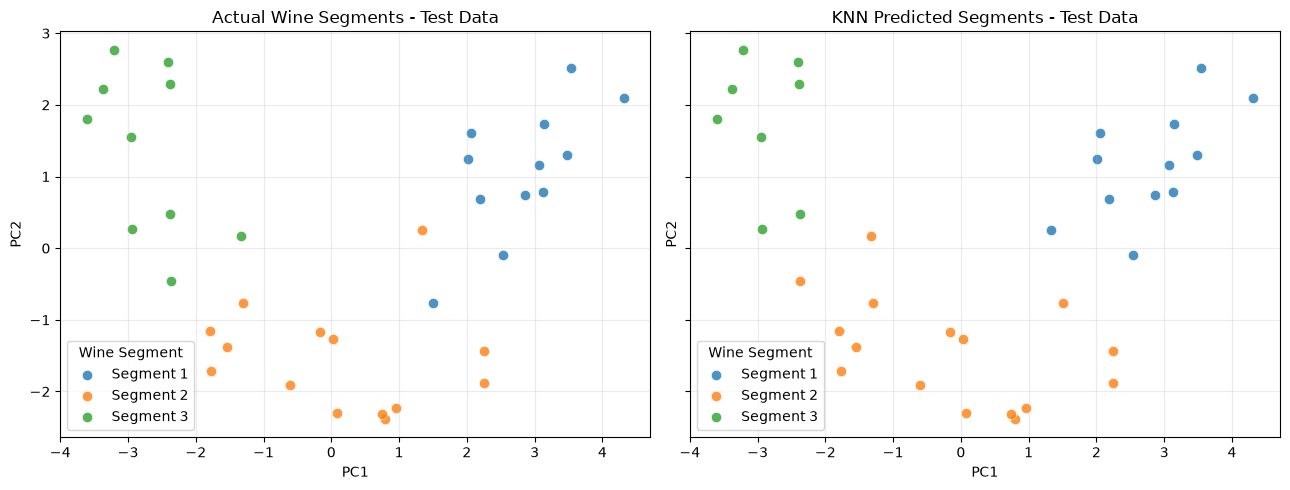

In [20]:

# Compare the SAME held-out wines at the SAME PC1/PC2 positions.
segment_labels = sorted(y.unique())

segment_colors = {
    segment_labels[0]: "tab:blue",
    segment_labels[1]: "tab:orange",
    segment_labels[2]: "tab:green"
}

fig, axes = plt.subplots(
    1, 2, figsize=(13, 5), sharex=True, sharey=True
)

for ax, labels, title in zip(
    axes,
    [y_test.to_numpy(), y_test_pred],
    [
        "Actual Wine Segments - Test Data",
        "KNN Predicted Segments - Test Data"
    ]
):
    for segment in segment_labels:
        mask = np.asarray(labels) == segment

        ax.scatter(
            X_test.loc[mask, "PC1"],
            X_test.loc[mask, "PC2"],
            color=segment_colors[segment],
            label=f"Segment {segment}",
            alpha=0.8,
            edgecolors="white",
            linewidths=0.5,
            s=55
        )

    ax.set(
        xlabel="PC1",
        ylabel="PC2",
        title=title
    )

    ax.legend(title="Wine Segment")
    ax.grid(alpha=0.25)

plt.tight_layout()
plt.show()
